In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
full_path = os.path.join(path, csv_file)

df = pd.read_csv(full_path)
print(f"Dataset successfully loaded! Rows count: {df.shape[0]}, Columns count: {df.shape[1]}")

100%|██████████| 8.17M/8.17M [00:02<00:00, 3.40MB/s]

Extracting files...


Dataset úspěšně načten! Počet řádků: 114000, Počet sloupců: 21


## 1. Data Inspection
Before we begin cleaning the data, we need to understand what kind of data we’re working with. We’ll look at data types, the presence of missing values (NaN), and which columns will be unnecessary for our model (e.g., unique identifiers).

In [ ]:

display(df.head())

# Základní informace o sloupcích a datových typech
df.info()

# Kontrola chybějících hodnot
print("\nEmpty values:")
print(df.isnull().sum())

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

## 2. Data Cleaning & Preprocessing
Based on the initial inspection, the dataset is relatively clean, but it requires a few active steps to meet all of the constraints and ensure the models perform well:

1. **Handling Missing Values:** Only 1 out of 114,000 rows has missing values (NaN) in the `artists`, `album_name`, and `track_name` columns. Imputation is unnecessary here; we will simply drop this single row, as it is statistically insignificant.
2. **Dropping Irrelevant Columns:** The `Unnamed: 0` column is just an index artifact, and `track_id` is a unique string identifier. Neither provides any predictive value for clustering or classification, so they will be dropped.
3. **Handling Duplicates:** A track might be listed multiple times if it belongs to multiple genres. To prevent data leakage and bias, we will remove exact duplicates based on the `track_name` and `artists`.

In [4]:
# 1. Drop the single row with missing values
df.dropna(inplace=True)

# 2. Drop irrelevant columns
df.drop(columns=['Unnamed: 0', 'track_id'], inplace=True)

# 3. Handle duplicates
# We drop duplicates where BOTH the track name and artist are exactly the same
initial_rows = df.shape[0]
df.drop_duplicates(subset=['track_name', 'artists'], keep='first', inplace=True)
final_rows = df.shape[0]

print(f"Removed {initial_rows - final_rows} duplicate tracks.")
print(f"Data shape after cleaning: {df.shape}")

Removed 32656 duplicate tracks.
Data shape after cleaning: (81343, 19)


## 3. Feature Engineering
To add depth to the dataset based on domain logic (musical characteristics), we will create two new variables:

1. **`complexity_index`**: A combination of `instrumentalness` and the inverse of `danceability`. Highly complex music (like art rock or classical) often has high instrumentalness but is harder to dance to.
2. **`energy_acoustic_ratio`**: Pop and electronic music often rely on high energy and low acousticness, while folk or indie rock might have lower energy but high acousticness. This ratio creates a new single axis separating synthetic from organic sounds.

In [5]:
# Create complexity_index
# We use (1 - danceability) because less danceable often implies more complex rhythmic structures
df['complexity_index'] = df['instrumentalness'] * (1 - df['danceability'])

# Create energy_acoustic_ratio
# We add a small constant (0.01) to the denominator to prevent division by zero
df['energy_acoustic_ratio'] = df['energy'] / (df['acousticness'] + 0.01)

# Let's check our new features
display(df[['track_name', 'artists', 'complexity_index', 'energy_acoustic_ratio']].head())

,track_name,artists,complexity_index,energy_acoustic_ratio
0,Comedy,Gen Hoshino,3.272400e-07,10.924171
1,Ghost - Acoustic,Ben Woodward,3.224800e-06,0.177730
2,To Begin Again,Ingrid Michaelson;ZAYN,0.000000e+00,1.631818
3,Can't Help Falling In Love,Kina Grannis,5.189380e-05,0.065137
4,Hold On,Chord Overstreet,0.000000e+00,0.924843


## 4. Exploratory Data Analysis (EDA)
Now that the data is clean and enriched, we will perform visual exploration.

### 4.1 Univariate Analysis: Distributions
First, we look at the distributions of `danceability` and `energy` to understand if our data follows a normal distribution.

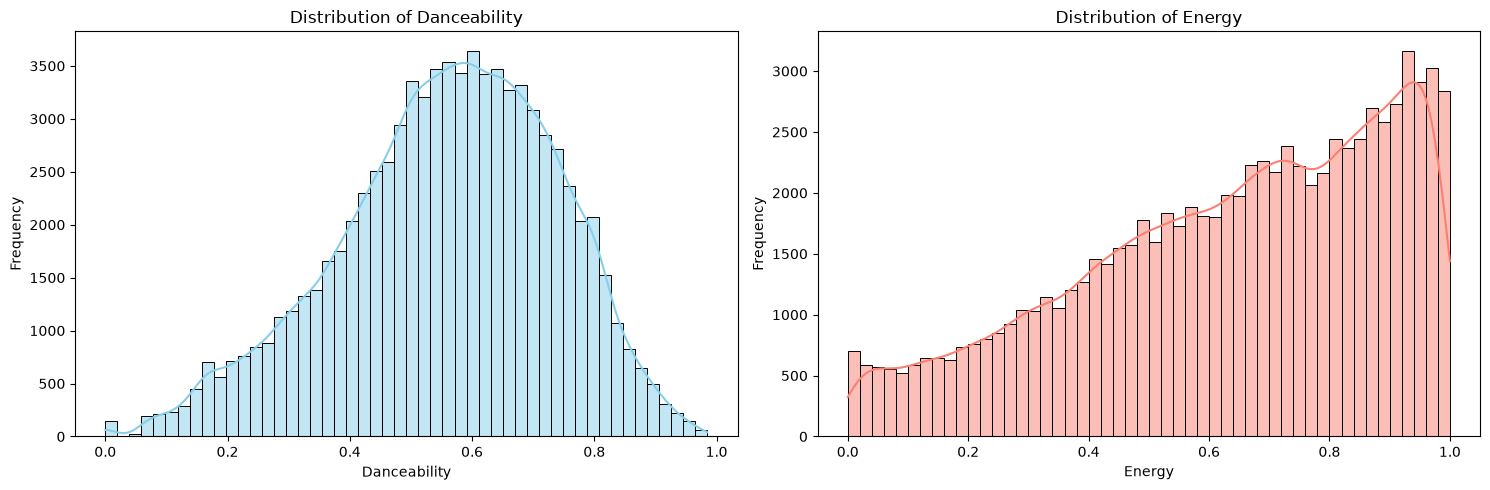

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['danceability'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Danceability')
axes[0].set_xlabel('Danceability')
axes[0].set_ylabel('Frequency')

sns.histplot(df['energy'], bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Energy')
axes[1].set_xlabel('Energy')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 4.2 Bivariate Analysis: The Axis of Melancholy (Valence vs. Energy)
To understand the emotional landscape of the dataset, we will map `valence` (how positive/happy a track sounds) against `energy` (intensity and activity). This creates four distinct emotional quadrants. 

Because plotting 114,000 points on a standard scatter plot causes severe overplotting, we will use a 2D histogram (density plot) to reveal where the majority of modern music lies, and define our quadrants using threshold lines.

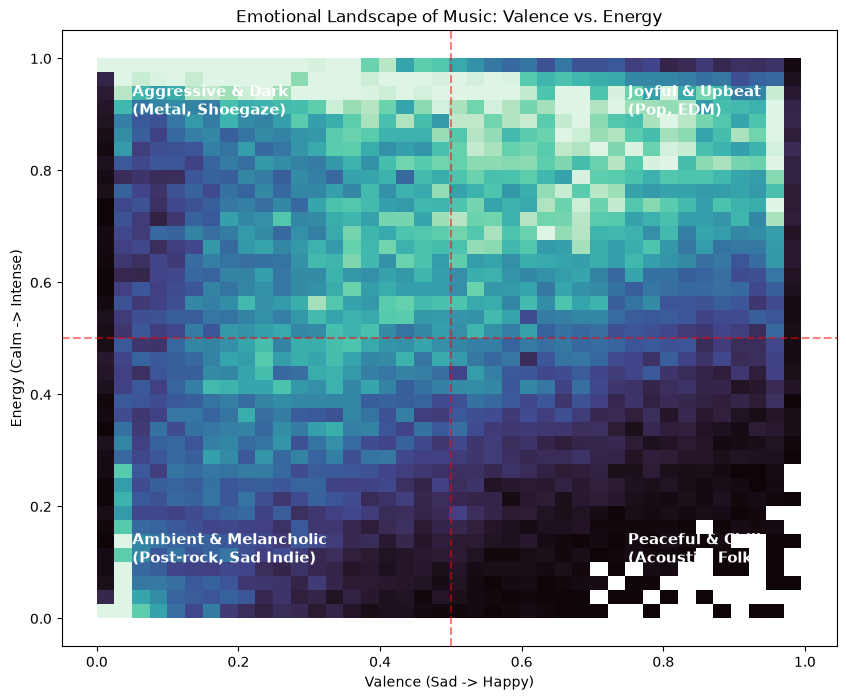

In [7]:
plt.figure(figsize=(10, 8))

# We use a 2D histogram (hexbin or histplot) to handle the massive volume of data gracefully
sns.histplot(data=df, x='valence', y='energy', bins=40, cmap='mako', pmax=0.9)

# Drawing threshold lines to separate the quadrants
plt.axvline(x=0.5, color='red', linestyle='--', alpha=0.5)
plt.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)

# Adding domain-specific annotations for the quadrants
plt.text(0.05, 0.1, 'Ambient & Melancholic\n(Post-rock, Sad Indie)', color='white', fontsize=11, weight='bold')
plt.text(0.05, 0.9, 'Aggressive & Dark\n(Metal, Shoegaze)', color='white', fontsize=11, weight='bold')
plt.text(0.75, 0.1, 'Peaceful & Chill\n(Acoustic, Folk)', color='white', fontsize=11, weight='bold')
plt.text(0.75, 0.9, 'Joyful & Upbeat\n(Pop, EDM)', color='white', fontsize=11, weight='bold')

plt.title('Emotional Landscape of Music: Valence vs. Energy')
plt.xlabel('Valence (Sad -> Happy)')
plt.ylabel('Energy (Calm -> Intense)')
plt.show()

**Interpretation of the Emotional Landscape:**
The plot reveals that the music industry is heavily concentrated in the top-right quadrant (high energy, high valence), representing standard upbeat Pop and EDM. 

However, as a data detective looking for atmospheric and complex music, we are interested in the extreme left side (`valence` < 0.3). 
* The **bottom-left quadrant** holds tracks with low energy and low valence (ambient, depressive, cinematic soundscapes).
* The **top-left quadrant** represents high energy but low valence, perfectly capturing heavy, distorted, or emotionally aggressive genres like Shoegaze or Post-Hardcore.

In [10]:
# Let's validate our domain logic by fetching a sample of tracks from the "Melancholic & Ambient" corner
# Criteria: Valence < 0.15 (very sad/dark) and Energy < 0.15 (very calm/ambient)

melancholic_tracks = df[(df['valence'] < 0.15) & (df['energy'] < 0.15)]

# Displaying a random sample of 5 tracks from this emotional quadrant
print("Sample tracks from the Melancholic & Ambient quadrant:")
display(melancholic_tracks[['artists', 'track_name', 'track_genre', 'valence', 'energy']].sample(30, random_state=42))

Sample tracks from the Melancholic & Ambient quadrant:


,artists,track_name,track_genre,valence,energy
39316,Hans Zimmer;Richard Harvey,Daniel's 9th Cipher,german,0.0267,0.069300
59152,Siavash Amini,All That Remained Pt.2,iranian,0.0303,0.120000
79559,Biba Dupont,Shared Shelter,piano,0.1430,0.045100
4871,Gabríel Ólafs,Absent Minded,ambient,0.0776,0.078100
36147,Jules Massenet;Michel Schwalbé;Berliner Philha...,Thaïs / Acte Deux: Meditation,french,0.0371,0.082500
79525,Ed Chinaski,For Kate,piano,0.1280,0.054600
16378,Maurice Ravel;Yukie Nagai,"Miroirs, M. 43: V. La vallée des cloches",classical,0.0394,0.000756
26931,The Sleep Diaries,"When You Wish Upon a Star (from ""Pinocchio"")",disney,0.1190,0.013400
93557,Валерий Агафонов,"В час, когда мерцанье...",romance,0.0395,0.075700
64875,Friðrik Karlsson,Nýtt líf,jazz,0.0386,0.071500
